# Linear Regression: predicting the output of a power plant

**Goal.** Learn a straight-line relationship between inputs and a numeric output.

**The model.** Linear regression predicts with a weighted sum of the features:

$$\hat y = b_0 + b_1 x_1 + b_2 x_2 + \dots + b_p x_p$$

The weights are chosen to minimize the mean squared error between predictions and true values.

**The dataset.** *Combined Cycle Power Plant* (UCI): 9,568 hourly measurements from a real plant.

| Column | Meaning |
|---|---|
| AT | Ambient temperature (°C) |
| V | Exhaust vacuum (cm Hg) |
| AP | Ambient pressure (mbar) |
| RH | Relative humidity (%) |
| **PE** | **Net electrical output (MW), the target** |

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "certifi": "certifi",
    "openpyxl": "openpyxl"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 1. Get the data

In [3]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

DATA_DIR = Path("data") / "ccpp"
archive = download("https://archive.ics.uci.edu/static/public/294/combined+cycle+power+plant.zip", DATA_DIR / "dataset.zip")
with zipfile.ZipFile(archive) as z:
    z.extractall(DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.rglob("*") if p.is_file()][:10])

Downloading: https://archive.ics.uci.edu/static/public/294/combined+cycle+power+plant.zip


Saved: data\ccpp\dataset.zip (3.7 MB)
Files: ['dataset.zip', 'Folds5x2_pp.ods', 'Folds5x2_pp.xlsx', 'Readme.txt', 'Readme.txt~']


In [4]:
import pandas as pd

# The workbook holds several shuffled copies of the same data. We only need the first sheet.
df = pd.read_excel(DATA_DIR / "CCPP" / "Folds5x2_pp.xlsx", sheet_name=0)
print("Shape:", df.shape, "| Missing values:", int(df.isna().sum().sum()))
df.describe().round(2)

Shape: (9568, 5) | Missing values: 0


,AT,V,AP,RH,PE
count,9568.00,9568.00,9568.00,9568.00,9568.00
mean,19.65,54.31,1013.26,73.31,454.37
std,7.45,12.71,5.94,14.60,17.07
min,1.81,25.36,992.89,25.56,420.26
25%,13.51,41.74,1009.10,63.33,439.75
50%,20.34,52.08,1012.94,74.97,451.55
75%,25.72,66.54,1017.26,84.83,468.43
max,37.11,81.56,1033.30,100.16,495.76


## 2. Split into train and test
The test set is locked away and used only once, at the very end.

In [5]:
from sklearn.model_selection import train_test_split

X = df[["AT", "V", "AP", "RH"]]
y = df["PE"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (7654, 4) Test: (1914, 4)


## 3. Train the model
A `Pipeline` first scales the features and then fits the regression. With scaled features, the size of each weight can be compared directly.

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model = make_pipeline(StandardScaler(), LinearRegression())
model.fit(X_train, y_train)

regression = model.named_steps["linearregression"]
weights = pd.Series(regression.coef_, index=X.columns).sort_values()
print("Intercept (average output, MW):", round(regression.intercept_, 2))
print(weights.round(3))

Intercept (average output, MW):

 454.43
AT   -14.764
V     -2.950
RH    -2.312
AP     0.370
dtype: float64


## 4. Evaluate on unseen data
- **MAE**: average size of the error, in MW.
- **RMSE**: like MAE, but punishes large errors more.
- **R²**: share of the output's variation that the model explains (1 is perfect, 0 is no better than predicting the mean).

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score

y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
r2 = r2_score(y_test, y_pred)

# 5-fold cross-validation on the training set: is the score stable across different splits?
cv_r2 = cross_val_score(model, X_train, y_train, cv=5, scoring="r2")
print(f"MAE = {mae:.2f} MW | RMSE = {rmse:.2f} MW | R2 = {r2:.4f}")
print(f"Cross-validated R2 = {cv_r2.mean():.4f} +/- {cv_r2.std():.4f}")

MAE = 3.60 MW | RMSE = 4.50 MW | R2 = 0.9301
Cross-validated R2 = 0.9282 +/- 0.0031


## 5. Look at the results
Points on the diagonal are perfect predictions. Residuals should be centered on zero.

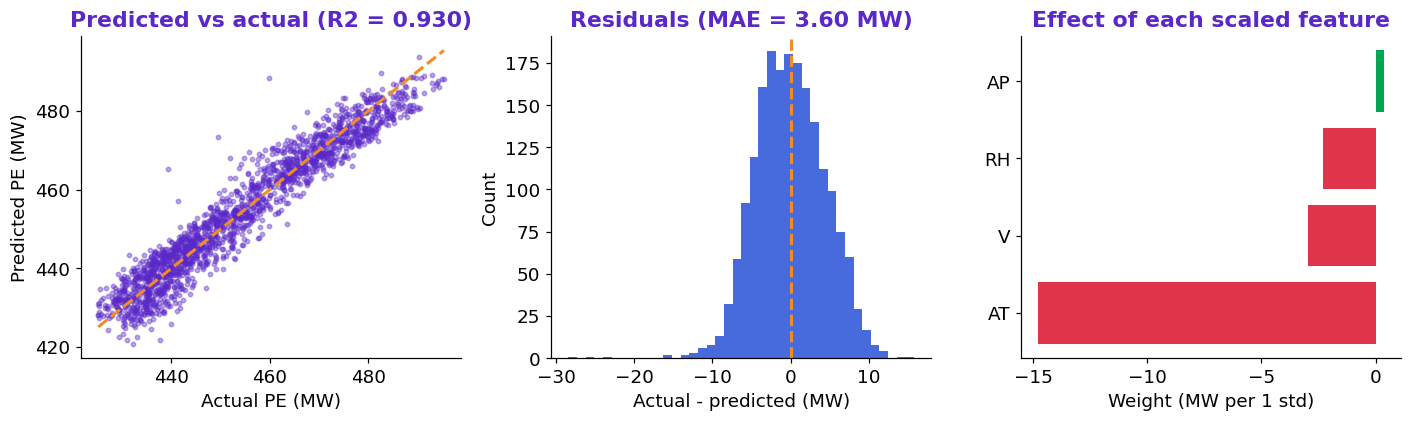

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].scatter(y_test, y_pred, s=8, alpha=0.4, color=PURPLE)
limits = [y_test.min(), y_test.max()]
ax[0].plot(limits, limits, "--", color=ORANGE, lw=2)
ax[0].set(title=f"Predicted vs actual (R2 = {r2:.3f})", xlabel="Actual PE (MW)", ylabel="Predicted PE (MW)")

ax[1].hist(y_test - y_pred, bins=40, color=BLUE)
ax[1].axvline(0, color=ORANGE, lw=2, ls="--")
ax[1].set(title=f"Residuals (MAE = {mae:.2f} MW)", xlabel="Actual - predicted (MW)", ylabel="Count")

ax[2].barh(weights.index, weights.values, color=[RED if v < 0 else GREEN for v in weights.values])
ax[2].set(title="Effect of each scaled feature", xlabel="Weight (MW per 1 std)")
fig.tight_layout()
plt.show()

In [9]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "01_linear_regression.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "Linear Regression",
    "dataset": "Combined Cycle Power Plant (UCI)",
    "n_samples": int(len(df)),
    "metrics": {"MAE (MW)": round(mae, 2), "RMSE (MW)": round(rmse, 2), "R2": round(r2, 4), "CV R2": round(float(cv_r2.mean()), 4)},
}
(results_dir / "01_linear_regression.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "Linear Regression",
  "dataset": "Combined Cycle Power Plant (UCI)",
  "n_samples": 9568,
  "metrics": {
    "MAE (MW)": 3.6,
    "RMSE (MW)": 4.5,
    "R2": 0.9301,
    "CV R2": 0.9282
  }
}


## What to remember
- A simple linear model can already be accurate when the relation is close to linear.
- Temperature (AT) has the strongest effect: a hotter day means less power.
- **Try it yourself:** remove `AT` from the features and compare R².